# 01 · Exploración de los datos

**Proyecto:** Mercado solar en Cuba — comparación de salarios y precio de paneles solares.

**Objetivo de este notebook:** aprender a cargar un archivo de datos y a *mirarlo* antes de analizarlo. Eso se llama **exploración de datos (EDA)** y es siempre el primer paso de un proyecto de ciencia de datos.

Al terminar sabrás:

1. Qué es un notebook y cómo ejecutar celdas.
2. Cargar un CSV con `pandas`.
3. Qué significan `.head()`, `.shape`, `.info()` y `.describe()`.
4. Por qué el texto `PENDIENTE` rompe los cálculos y cómo convertirlo en datos faltantes.
5. Hacer tu primer gráfico.

## 0 · Cómo usar este notebook

- Hay dos tipos de celdas: **texto** (como esta) y **código** (abajo, con `In [ ]:`).
- Se ejecuta una celda con **`Shift + Enter`**.
- El número entre corchetes `In [ ]:` está vacío = la celda no se ha ejecutado aún.
- Si ejecutas **todas las celdas en orden**, no deberías tener errores.

> Regla de oro: **ejecuta en orden y entiende cada celda antes de pasar a la siguiente.**

## 1 · Imports: las herramientas que usaremos

- **`pandas`**: la librería de Python para trabajar con tablas de datos (tipo Excel, pero en código). Su objeto principal es el `DataFrame`.
- **`matplotlib`**: para hacer gráficos.
- **`pathlib`**: para rutas de archivos, así no nos perdemos entre carpetas.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print('pandas', pd.__version__)

pandas 3.0.6


## 2 · Encontrar los datos

Los datos viven en `data/raw/`. Como Jupyter puede abrirse desde la carpeta del proyecto o desde `notebooks/`, buscamos la carpeta `data` que esté más cerca. No hace falta que memorices esto: solo evita el error *"archivo no encontrado"*.

In [5]:
RAIZ = Path.cwd()
if not (RAIZ / 'data').exists():
    RAIZ = RAIZ.parent

print('Proyecto encontrado en:', RAIZ)

Proyecto encontrado en: c:\Users\ok\Documents\Default Project\solarrr\cuba_solar_market\mercado_solar


## 3 · Cargar el CSV

`read_csv` = *"leer archivo con valores separados por comas"*. Devuelve un **DataFrame**: una tabla con filas (cada fila = un año) y columnas (cada columna = una variable).

In [8]:
salarios = pd.read_csv(RAIZ / 'data' / 'raw' / 'salarios_cuba.csv')
salarios

,anio,salario_medio_cup,salario_minimo_cup,fuente,verificado
0,2016,740,PENDIENTE,ONEI Cuba,no
1,2017,767,PENDIENTE,ONEI Cuba,no
2,2018,777,PENDIENTE,ONEI Cuba,no
3,2019,879,PENDIENTE,ONEI Cuba,no
4,2020,1194,PENDIENTE,ONEI Cuba,no
5,2021,3849,PENDIENTE,ONEI Cuba,no
6,2022,4209,PENDIENTE,ONEI Cuba,no
7,2023,4654,PENDIENTE,ONEI Cuba,no
8,2024,5839,PENDIENTE,ONEI Cuba,no
9,2025,6930,PENDIENTE,ONEI Cuba,no


## 4 · Mirar la tabla

Cuatro preguntas que siempre se hacen al cargar datos nuevos:

| Pregunta | Comando |
|---|---|
| ¿Cómo son las primeras filas? | `.head()` |
| ¿Cuántas filas y columnas hay? | `.shape` |
| ¿Qué tipo tiene cada columna? | `.info()` |
| ¿Qué resumen numérico da? | `.describe()` |

In [9]:
salarios.head()

,anio,salario_medio_cup,salario_minimo_cup,fuente,verificado
0,2016,740,PENDIENTE,ONEI Cuba,no
1,2017,767,PENDIENTE,ONEI Cuba,no
2,2018,777,PENDIENTE,ONEI Cuba,no
3,2019,879,PENDIENTE,ONEI Cuba,no
4,2020,1194,PENDIENTE,ONEI Cuba,no


In [10]:
print('Filas y columnas:', salarios.shape)
print('Nombres de columnas:', list(salarios.columns))

Filas y columnas: (11, 5)
Nombres de columnas: ['anio', 'salario_medio_cup', 'salario_minimo_cup', 'fuente', 'verificado']


In [11]:
salarios.info()

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   anio                11 non-null     int64
 1   salario_medio_cup   11 non-null     int64
 2   salario_minimo_cup  11 non-null     str  
 3   fuente              11 non-null     str  
 4   verificado          11 non-null     str  
dtypes: int64(2), str(3)
memory usage: 572.0 bytes


### Qué nos dice `.info()`

- `RangeIndex: 10 entries` → **10 filas** (los años 2016 a 2025).
- `salario_medio_cup    non-null  str` → `str` (en versiones antiguas de pandas aparecía `object`) significa **texto**, no número.

Eso es un problema: una columna de texto **no se puede promediar**. La causa es que las celdas dicen `PENDIENTE` en lugar de tener un número.

In [12]:
salarios.dtypes

anio                  int64
salario_medio_cup     int64
salario_minimo_cup      str
fuente                  str
verificado              str
dtype: object

## 5 · El problema de `PENDIENTE`

Queremos que `salario_medio_cup` sea numérica. Usamos `pd.to_numeric(..., errors='coerce')`:

- intenta convertir cada celda a número,
- lo que no se pueda convertir (como `PENDIENTE`) lo convierte en **`NaN`** (*Not a Number*, dato faltante).

`NaN` es el estándar para decir *"aquí no hay dato"* — y es mucho mejor que texto, porque pandas lo **ignora** al calcular promedios en vez de dar un error.

In [13]:
salarios_limpios = salarios.copy()

for columna in ['salario_medio_cup', 'salario_minimo_cup']:
    salarios_limpios[columna] = pd.to_numeric(
        salarios_limpios[columna], errors='coerce'
    )

salarios_limpios.dtypes

anio                    int64
salario_medio_cup       int64
salario_minimo_cup    float64
fuente                    str
verificado                str
dtype: object

In [14]:
print('Valores faltantes por columna (NaN):')
salarios_limpios.isna().sum()

Valores faltantes por columna (NaN):


anio                   0
salario_medio_cup      0
salario_minimo_cup    10
fuente                 0
verificado             0
dtype: int64

### Interpretación

`salario_medio_cup: 10` → los 10 años están sin dato. **Esto es correcto y esperado**: todavía no hemos buscado las cifras del ONEI.

Estas 10 filas son exactamente tu trabajo en la Fase 2 (ver al final de este notebook).

## 6 · Resumen numérico con `describe()`

Devuelve conteo, media, desviación típica, mínimos y máximos. **Ignora los `NaN`**.

In [15]:
salarios_limpios.describe()

,anio,salario_medio_cup,salario_minimo_cup
count,11.000000,11.000000,1.0
mean,2021.000000,3381.090909,3210.0
std,3.316625,2618.753461,NaN
min,2016.000000,740.000000,3210.0
25%,2018.500000,828.000000,3210.0
50%,2021.000000,3849.000000,3210.0
75%,2023.500000,5246.500000,3210.0
max,2026.000000,7354.000000,3210.0


Ahora mismo `count = 0`, porque no hay ningún número todavía. Cuando rellenes el CSV verás aquí, por ejemplo, `mean` (media del salario medio entre 2016 y 2025).

## 7 · Tu primer gráfico

Un gráfico de líneas con los años en el eje X y los CUP mensuales en el eje Y. Fíjate en que **siempre** se ponen título y etiquetas a los ejes: sin ellas, un gráfico no comunica nada.

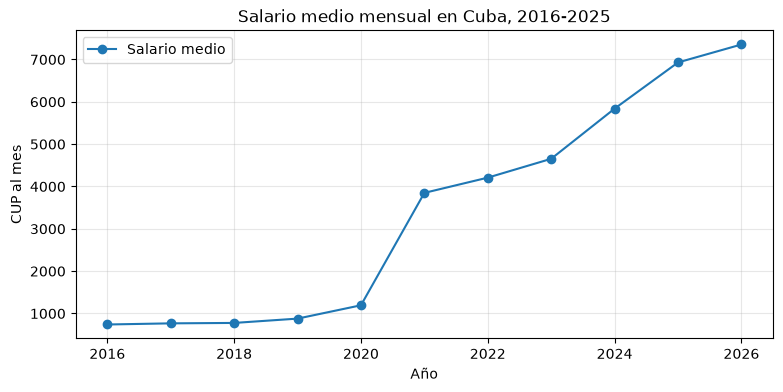

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    salarios_limpios['anio'],
    salarios_limpios['salario_medio_cup'],
    marker='o',
    label='Salario medio',
)

ax.set_title('Salario medio mensual en Cuba, 2016-2025')
ax.set_xlabel('Año')
ax.set_ylabel('CUP al mes')
ax.grid(alpha=0.3)
ax.legend()

plt.show()

### ¿Por qué sale un gráfico "vacío"?

Porque todos los valores son `NaN` y matplotlib **no dibuja líneas sin puntos**. No es un error: es el gráfico honesto de *"aún no hay datos"*.

Vuelve a ejecutar esta celda después de rellenar el CSV y la línea aparecerá. Ese será un buen momento para tomarte una foto y añadirla a tu entrega.

## 8 · Tu tarea antes del notebook 02

1. Busca en Google: **`ONEI anuario estadístico de Cuba salarios medios`** (onei.cu).
2. Localiza la tabla de **salarios medios por año** (también sirve *salario medio de la economía* o *por sector*).
3. Rellena `data/raw/salarios_cuba.csv` respetando las columnas: `anio, salario_medio_cup, salario_minimo_cup, fuente, verificado`.
4. En `fuente` escribe de dónde salió el dato (nombre del anuario + tabla/página).
5. Si un año no aparece, **déjalo como `PENDIENTE`**: no inventes cifras.
6. Cambia `verificado` a `yes` solo cuando hayas comprobado el número dos veces.

> Regla de oro del proyecto: **sin fuente, el dato no existe**.

## Glosario

| Término | Significado |
|---|---|
| **DataFrame** | Tabla de filas y columnas, el objeto central de pandas |
| **CSV** | Archivo de texto con valores separados por comas |
| **NaN** | *Not a Number*: dato faltante |
| **EDA** | *Exploratory Data Analysis*: explorar antes de analizar |
| **Serie** | Una sola columna de un DataFrame |
| **`.head()`** | Muestra las primeras 5 filas |
| **`.shape`** | Devuelve `(filas, columnas)` |
| **`.isna()`** | Marca qué celdas están vacías/NaN |